In [9]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import pandas as pd
import seaborn as sns

dane = pd.read_csv('housing_cleaned.csv')

print(dane.head(1))
print(dane.columns)

nadmorskie = dane[dane['ocean_proximity'].isin(['NEAR BAY', 'NEAR OCEAN', '1H OCEAN'])]
lądowe = dane[dane['ocean_proximity'].isin(['INLAND', 'ISLAND'])]


   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0          880             129   

   population  households  median_income  median_house_value ocean_proximity  \
0         322         126         8.3252               45.26        NEAR BAY   

   ...  price_to_monthly_income_ratio  total_rooms_log  total_bedrooms_log  \
0  ...                           5.44         6.779922            4.859812   

   population_log  households_log  median_income_log  \
0        5.774552        4.836282           2.119287   

   population_per_household_log  rooms_per_household_log  \
0                      0.940007                 1.943049   

   bedrooms_per_person_log  price_to_monthly_income_ratio_log  
0                 0.336472                           1.693779  

[1 rows x 24 columns]
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       

In [10]:
#prototyp funkcji do obliczania statystyk opisowych dla danej grupy danych
'''# --- OBLICZENIE STATYSTYK ---
skosnosc = dane.skew(numeric_only=True)
kurtoza = dane.kurt(numeric_only=True)

skosnosc_ladowe = lądowe.skew(numeric_only=True)
kurtoza_ladowe = lądowe.kurt(numeric_only=True)

skosnosc_nadmorskie = nadmorskie.skew(numeric_only=True)
kurtoza_nadmorskie = nadmorskie.kurt(numeric_only=True)

# --- CAŁOŚĆ ---
print("--- CAŁOŚĆ ---")
print("Kwantyle dochodu:\n", dane['median_income'].quantile([0.25, 0.75, 0.9]))
print("IQR dochodu:", dane['median_income'].quantile(0.75) - dane['median_income'].quantile(0.25))
print("Odchylenie standardowe dochodu:", dane['median_income'].std().__round__(2))
print("Wariancja dochodu:", dane['median_income'].var().__round__(2))
print("Skośność dochodu:", skosnosc['median_income'].__round__(2))
print("Kurtoza dochodu:", kurtoza['median_income'].__round__(2))
print("\n" + "="*50 + "\n")

print("Kwantyle ceny domów:\n", dane['median_house_value'].quantile([0.25, 0.75, 0.9]))
print("IQR ceny domów:", dane['median_house_value'].quantile(0.75) - dane['median_house_value'].quantile(0.25))
print("Odchylenie standardowe ceny domów:", dane['median_house_value'].std().__round__(2))
print("Wariancja ceny domów:", dane['median_house_value'].var().__round__(2))
print("Skośność ceny domów:", skosnosc['median_house_value'].__round__(2))
print("Kurtoza ceny domów:", kurtoza['median_house_value'].__round__(2))
print("\n" + "="*50 + "\n")

# --- OBSZARY NADMORSKIE ---
print("--- OBSZARY NADMORSKIE ---")
print("Kwantyle dochodu:\n", nadmorskie['median_income'].quantile([0.25, 0.75, 0.9]))
print("IQR dochodu:", nadmorskie['median_income'].quantile(0.75) - nadmorskie['median_income'].quantile(0.25))
print("Odchylenie standardowe dochodu:", nadmorskie['median_income'].std().__round__(2))
print("Wariancja dochodu:", nadmorskie['median_income'].var().__round__(2))
print("Skośność dochodu (nadmorskie):", skosnosc_nadmorskie['median_income'].__round__(2))
print("Kurtoza dochodu (nadmorskie):", kurtoza_nadmorskie['median_income'].__round__(2))

print("\nKwantyle ceny domów:\n", nadmorskie['median_house_value'].quantile([0.25, 0.75, 0.9]))
print("IQR ceny domów:", nadmorskie['median_house_value'].quantile(0.75) - nadmorskie['median_house_value'].quantile(0.25))
print("Odchylenie standardowe ceny domów:", nadmorskie['median_house_value'].std().__round__(2))
print("Wariancja ceny domów:", nadmorskie['median_house_value'].var().__round__(2))
print("Skośność ceny domów (nadmorskie):", skosnosc_nadmorskie['median_house_value'].__round__(2))
print("Kurtoza ceny domów (nadmorskie):", kurtoza_nadmorskie['median_house_value'].__round__(2))
print("\n" + "="*50 + "\n")

# --- OBSZARY LĄDOWE ---
print("--- OBSZARY LĄDOWE ---")
print("Kwantyle dochodu:\n", lądowe['median_income'].quantile([0.25, 0.75, 0.9]))
print("IQR dochodu:", lądowe['median_income'].quantile(0.75) - lądowe['median_income'].quantile(0.25))
print("Odchylenie standardowe dochodu:", lądowe['median_income'].std().__round__(2))
print("Wariancja dochodu:", lądowe['median_income'].var().__round__(2))
print("Skośność dochodu (lądowe):", skosnosc_ladowe['median_income'].__round__(2))
print("Kurtoza dochodu (lądowe):", kurtoza_ladowe['median_income'].__round__(2))

print("\nKwantyle ceny domów:\n", lądowe['median_house_value'].quantile([0.25, 0.75, 0.9]))
print("IQR ceny domów:", lądowe['median_house_value'].quantile(0.75) - lądowe['median_house_value'].quantile(0.25))
print("Odchylenie standardowe ceny domów:", lądowe['median_house_value'].std().__round__(2))
print("Wariancja ceny domów:", lądowe['median_house_value'].var().__round__(2))
print("Skośność ceny domów (lądowe):", skosnosc_ladowe['median_house_value'].__round__(2))
print("Kurtoza ceny domów (lądowe):", kurtoza_ladowe['median_house_value'].__round__(2))'''

'# --- OBLICZENIE STATYSTYK ---\nskosnosc = dane.skew(numeric_only=True)\nkurtoza = dane.kurt(numeric_only=True)\n\nskosnosc_ladowe = lądowe.skew(numeric_only=True)\nkurtoza_ladowe = lądowe.kurt(numeric_only=True)\n\nskosnosc_nadmorskie = nadmorskie.skew(numeric_only=True)\nkurtoza_nadmorskie = nadmorskie.kurt(numeric_only=True)\n\n# --- CAŁOŚĆ ---\nprint("--- CAŁOŚĆ ---")\nprint("Kwantyle dochodu:\n", dane[\'median_income\'].quantile([0.25, 0.75, 0.9]))\nprint("IQR dochodu:", dane[\'median_income\'].quantile(0.75) - dane[\'median_income\'].quantile(0.25))\nprint("Odchylenie standardowe dochodu:", dane[\'median_income\'].std().__round__(2))\nprint("Wariancja dochodu:", dane[\'median_income\'].var().__round__(2))\nprint("Skośność dochodu:", skosnosc[\'median_income\'].__round__(2))\nprint("Kurtoza dochodu:", kurtoza[\'median_income\'].__round__(2))\nprint("\n" + "="*50 + "\n")\n\nprint("Kwantyle ceny domów:\n", dane[\'median_house_value\'].quantile([0.25, 0.75, 0.9]))\nprint("IQR ceny d

In [11]:
# 3. Definicja funkcji podsumowującej statystyki
def full_advanced_summary(df, group_name="Całość"):
    stats = []
    columns = ['median_income', 'median_house_value']
    
    for col in columns:
        s = df[col]
        q25 = s.quantile(0.25)
        median = s.median()
        q75 = s.quantile(0.75)
        q90 = s.quantile(0.90)
        iqr = q75 - q25
        
        stats.append({
            'Grupa / Zmienna': f"{group_name} - {col}",
            'Średnia': s.mean(),
            'Q1 (25%)': q25,
            'Mediana': median,
            'Q3 (75%)': q75,
            'Q90 (90%)': q90,
            'IQR': iqr,
            'Odch. stand.': s.std(),
            'Wariancja': s.var(),
            'Skośność': s.skew(),
            'Kurtoza': s.kurt()
        })
    
    return pd.DataFrame(stats).set_index('Grupa / Zmienna')


tabela_calkowita = pd.concat([
    full_advanced_summary(dane, "Całość"),
    full_advanced_summary(nadmorskie, "Nadmorskie"),
    full_advanced_summary(lądowe, "Lądowe")
]).round(2)


display(tabela_calkowita)

,Średnia,Q1 (25%),Mediana,Q3 (75%),Q90 (90%),IQR,Odch. stand.,Wariancja,Skośność,Kurtoza
Grupa / Zmienna,,,,,,,,,,
Całość - median_income,3.87,2.56,3.53,4.74,6.16,2.18,1.90,3.61,1.65,4.95
Całość - median_house_value,20.69,11.96,17.97,26.47,37.66,14.51,11.54,133.16,0.98,0.33
Nadmorskie - median_income,4.08,2.71,3.73,4.95,6.50,2.24,2.01,4.06,1.63,4.47
Nadmorskie - median_house_value,25.41,15.63,23.17,33.53,46.35,17.90,12.27,150.66,0.58,-0.63
Lądowe - median_income,3.21,2.19,2.99,3.96,5.04,1.77,1.44,2.07,1.46,4.71
Lądowe - median_house_value,12.48,7.75,10.85,14.90,20.83,7.14,7.00,49.01,2.11,6.33


Mediana wartości nieruchomości w zbiorze wynosi 179,7 tys. USD, w obszarach nadmorskich zwiększa się do 231,7 tys. USD, natomiast na obszarach w głębi lądu spada do 108,5 tys. USD. Mediana dochodów zachowuje się podobnie i z średniej 35,3 tys. USD w obszarach nadmosrkich zwiększa sie do 37,3 tys. USD, natomiast w obszarach wgłębi lądu spada do 29,9 tys. USD. Wyniki wskazują na zróżnicowanie wartości nieruchomości i dochodów w zależności od położenia geograficznego.

In [12]:
zmienne_num = ['median_house_value', 'median_income', 'housing_median_age', 'total_rooms', 'population']
macierz_spearman = dane[zmienne_num].corr(method='spearman')
macierz_pearson = dane[zmienne_num].corr(method='pearson')

print("--- MACIERZ KORELACJI RANGOWEJ (SPEARMANA) ---")
display(macierz_spearman.round(2))



--- MACIERZ KORELACJI RANGOWEJ (SPEARMANA) ---


,median_house_value,median_income,housing_median_age,total_rooms,population
median_house_value,1.00,0.68,0.07,0.21,0.00
median_income,0.68,1.00,-0.15,0.27,0.01
housing_median_age,0.07,-0.15,1.00,-0.36,-0.28
total_rooms,0.21,0.27,-0.36,1.00,0.82
population,0.00,0.01,-0.28,0.82,1.00


Najsilniejsza dodatnia zależność z medianą wartości nieruchomości występuje z medianą dla dochodów i wynosi 0,68. Oznacza to że osoby z wyższymi dochodami posiadają na ogół nieruchomości o większej wartości. Wysoką korelację widać także między liczbą pokoi a liczbą mieszkańców. Korelację ujemną widać za to pomiędzy wiekiem budynków a liczbą pokoi oraz liczbą mieszkańców.

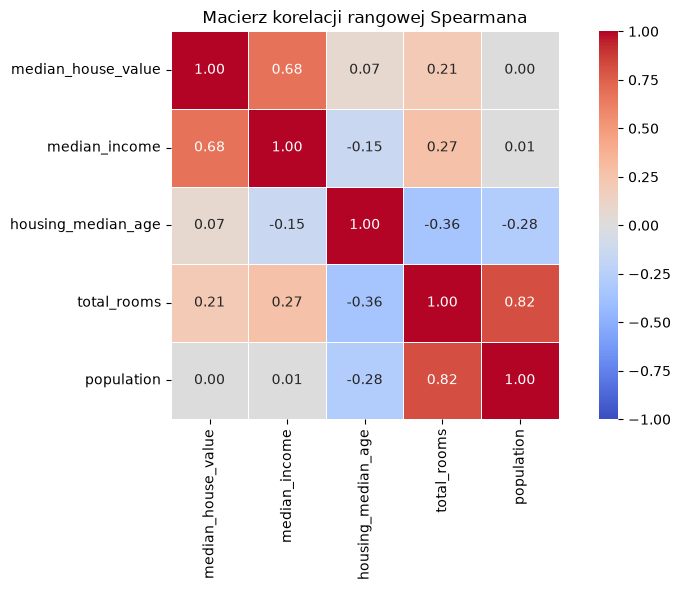

In [13]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    macierz_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title("Macierz korelacji rangowej Spearmana")
plt.tight_layout()
plt.show()

In [14]:
print("\n--- MACIERZ KORELACJI PEARSONA ---")
display(macierz_pearson.round(2))



--- MACIERZ KORELACJI PEARSONA ---


,median_house_value,median_income,housing_median_age,total_rooms,population
median_house_value,1.00,0.69,0.11,0.13,-0.02
median_income,0.69,1.00,-0.12,0.20,0.00
housing_median_age,0.11,-0.12,1.00,-0.36,-0.30
total_rooms,0.13,0.20,-0.36,1.00,0.86
population,-0.02,0.00,-0.30,0.86,1.00


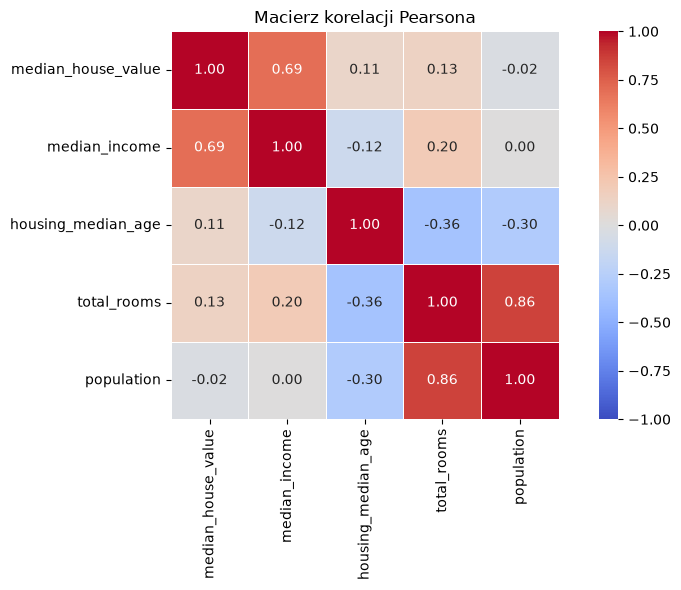

In [15]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    macierz_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title("Macierz korelacji Pearsona")
plt.tight_layout()
plt.show()

Najsilniejsza dodatnia zależność z medianą wartości nieruchomości występuje z medianą dla dochodów i wynosi 0,69. Oznacza to że osoby z wyższymi dochodami posiadają na ogół nieruchomości o większej wartości. Wysoką korelację widać także między liczbą pokoi a liczbą mieszkańców. Korelację ujemną widać za to pomiędzy wiekiem budynków a liczbą pokoi oraz liczbą mieszkańców.

In [16]:
print("\n--- ANALIZA ZMIENNEJ JAKOŚCIOWEJ: Ceny domów wg bliskości oceanu ---")
jakosciowa_analiza = dane.groupby('ocean_proximity')['median_house_value'].agg(
    Liczba_obserwacji='count',
    Średnia_cena='mean',
    Mediana_ceny='median',
    Odch_stand='std'
).round(2)

display(jakosciowa_analiza)


--- ANALIZA ZMIENNEJ JAKOŚCIOWEJ: Ceny domów wg bliskości oceanu ---


,Liczba_obserwacji,Średnia_cena,Mediana_ceny,Odch_stand
ocean_proximity,,,,
<1H OCEAN,9136,24.01,21.48,10.61
INLAND,6551,12.48,10.85,7.00
NEAR BAY,2290,25.92,23.38,12.28
NEAR OCEAN,2663,24.97,22.95,12.25


Najwyższą średnią cenę oraz medianę nieruchomości odnotowano blisko wybrzeża, gdzie kolejno mają one wartość 259,2 tys. USD oraz 233,8 tys. USD. Najniższe wartości notuje się wgłębi lądu, gdzie średnia wynosi 124,8 tys. USD, a mediana 108,5 tys. USD. Wynii wskazują na wyraźną różnice w wartościach nieruchomości pomiędzy analizowanymi obszarami geograficznymi.